# Case Study A — running the GUM uncertainty-quantification pipeline

This notebook executes the **actual analysis** behind this case study, end to end, as a
cell-by-cell walkthrough of `case_study_A_analysis.py` rather than a single opaque script run.
Every function used below — `load_zema`, `normalize_with_uncertainty`, `make_mlp`, `train`,
`propagate_lpu`, `propagate_mc`, `self_test_lpu` — is **imported unmodified** from that script.
What the notebook format adds that running the script from the CLI doesn't: intermediate
diagnostics and plots at every phase, inline, without separately running `make_validation_figure.py`.

It runs **two scenarios**:

- **Scenario A — raw features.** `cfg = Config()`, same defaults (`seed=0`) as the committed run,
  so the numbers should reproduce the headline results already in `README.md` /
  `case_study_A_report.md`.
- **Scenario B — trimmed features.** The same pipeline, but on the 1,084-dim feature set from
  `case_study_A_feature_trimming.ipynb` (`build_trimmed_dataset()`, dropping the leading
  acquisition-transient samples of Pneumatic pressure/Velocity/Axial force). That earlier notebook
  only checked the effect on point-prediction RMSE/R²; here the **full GUM uncertainty budget**
  (LPU, Monte Carlo, u_training, u_c, coverage) is recomputed for the trimmed inputs too, so the
  two scenarios can be compared on equal footing, not just on RMSE.

The five phases below (for each scenario) follow the script's own docstring, which maps directly
onto the paper's methodology: **Phase 1** regression task / measurand, **Phase 2** `u_training`
from a seed ensemble, **Phase 3** self-test gate for the analytical LPU, **Phase 4** `u_physical`
via LPU cross-checked against Monte Carlo, **Phase 5** aggregate validation.

**Runtime.** Each scenario trains a 10-seed MLP ensemble and then runs an analytical-LPU +
10,000-sample Monte Carlo propagation for each of the ~953 held-out test cycles — expect several
minutes per scenario. First execution also needs the ~2.7 GB ZeMA dataset, cached locally by
`zema_emc_annotated` after the first download.

**On disk effects.** This notebook does **not** overwrite the committed `case_study_A_results.csv`
(the official artifact behind the report and `zema_lpu_vs_mc.pdf`) — all results are kept in memory.


In [1]:
import sys
from pathlib import Path
import dataclasses
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

sys.path.insert(0, str(Path.cwd()))
from case_study_A_analysis import (  # reuse the pipeline's own code, unmodified
    Config, load_zema, normalize_with_uncertainty, make_mlp, train,
    propagate_lpu, propagate_mc, self_test_lpu,
)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 4)

cfg = Config()
dataclasses.asdict(cfg)


{'n_cycles': 4766,
 'datapoints_per_cycle': 100,
 'hidden': (128, 64, 32),
 'activation': 'softplus',
 'n_ensemble': 10,
 'n_mc': 10000,
 'test_fraction': 0.2,
 'epochs': 200,
 'lr': 0.001,
 'seed': 0}

## Phase 3 (gate) — validate the analytical LPU before touching real data

`self_test_lpu()` builds a small random softplus MLP, propagates a diagonal input covariance both
analytically (`propagate_lpu`) and via 200,000-sample Monte Carlo, and hard-asserts the two agree
within 2%. It needs no dataset. If this fails, the bug is in the propagation code, not in anything
downstream.


In [2]:
self_test_lpu()


[self-test] u_LPU=5.051898e-04  u_MC=5.056728e-04  rel.diff=0.096%


0.0009550534985251956

## Phase 1 — load the dataset and define the measurand

`load_zema(cfg)` returns the raw sensor values `X`, their per-sample standard uncertainties `UX`
(both shape `(N, 11*datapoints_per_cycle)`), and the target `y` — the consumed-lifetime fraction
`y_k = k/N`, deterministic by construction. See `case_study_A_eda.ipynb` for a full exploratory
look at `X`/`UX`; here we only confirm shapes before moving on. Also fix the train/test split here
(`cfg.seed`) once, so Scenario A and Scenario B use the *same* held-out cycles.


In [3]:
X, UX, y = load_zema(cfg)
CHANNEL_NAMES = [
    "Acceleration plain bearing", "Acceleration piston rod", "Acceleration ball bearing",
    "Active current", "Axial force",
    "Motor current phase 1", "Motor current phase 2", "Motor current phase 3",
    "Pneumatic pressure", "Sound pressure", "Velocity",
]
D = cfg.datapoints_per_cycle
N = X.shape[0]
print(f"X {X.shape}   UX {UX.shape}   y {y.shape}")
print(f"input dim = 11 channels x {D} datapoints/cycle = {X.shape[1]}")

rng = np.random.default_rng(cfg.seed)
idx = rng.permutation(N)
n_test = int(cfg.test_fraction * N)
te, tr = idx[:n_test], idx[n_test:]
print(f"train cycles: {len(tr)}   test cycles: {len(te)}")


X (4766, 1100)   UX (4766, 1100)   y (4766,)
input dim = 11 channels x 100 datapoints/cycle = 1100
train cycles: 3813   test cycles: 953


/Users/emanuelebuchicchio/repos/case_study_a/zema_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## A reusable pipeline runner

Both scenarios repeat the exact same steps (normalize -> train ensemble -> per-cycle LPU/MC ->
aggregate), only the feature matrix changes. Factoring that into one function keeps Scenario A and
Scenario B identical in every way except their inputs, and avoids drifting the two copies apart.


In [4]:
def run_pipeline(Xfeat, UXfeat, label):
    '''Runs Phases 2+4+5 of case_study_A_analysis.main() on a given feature matrix.'''
    mean, std = Xfeat[tr].mean(0), Xfeat[tr].std(0) + 1e-12
    Xn, UXn = normalize_with_uncertainty(Xfeat, UXfeat, mean, std)

    models, preds_te = [], []
    for s in range(cfg.n_ensemble):
        m = make_mlp(Xn.shape[1], cfg)
        train(m, Xn[tr], y[tr], cfg, seed=s)
        models.append(m)
        with torch.no_grad():
            preds_te.append(m(torch.tensor(Xn[te], dtype=torch.float64)).squeeze(1).numpy())
        print(f"  [{label}] seed {s} trained")
    preds_te = np.stack(preds_te)
    u_training = preds_te.std(axis=0, ddof=1)
    model = models[0]

    rows = []
    for j, i in enumerate(te):
        x = torch.tensor(Xn[i], dtype=torch.float64)
        ux = torch.tensor(UXn[i], dtype=torch.float64)
        yhat, U_y = propagate_lpu(model, x, torch.diag(ux ** 2))
        u_physical_lpu = math.sqrt(U_y.item())
        _, u_physical_mc = propagate_mc(model, x, ux, cfg.n_mc, seed=j)
        u_c = math.sqrt(u_physical_lpu ** 2 + u_training[j] ** 2)
        covered = abs(y[i] - yhat.item()) <= 2 * u_c
        rows.append((y[i], yhat.item(), u_physical_lpu, u_physical_mc, u_training[j], u_c, covered))
        if (j + 1) % 200 == 0 or (j + 1) == len(te):
            print(f"  [{label}] propagated {j + 1}/{len(te)} test cycles")

    r = np.array(rows, dtype=float)
    return r, models, preds_te


def summarize(r, label):
    resid = r[:, 0] - r[:, 1]
    rmse = np.sqrt(np.mean(resid ** 2))
    ss_res, ss_tot = np.sum(resid ** 2), np.sum((r[:, 0] - r[:, 0].mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    rel_diff = np.abs(r[:, 2] - r[:, 3]) / r[:, 3]
    coverage = r[:, 6].mean()
    out = {
        "scenario": label,
        "n_features": None,
        "rmse": rmse, "r2": r2,
        "mean_u_physical_lpu": r[:, 2].mean(),
        "mean_u_physical_mc": r[:, 3].mean(),
        "lpu_vs_mc_median_rel_diff": np.median(rel_diff),
        "mean_u_training": r[:, 4].mean(),
        "mean_u_c": r[:, 5].mean(),
        "coverage_k2": coverage,
    }
    print(f"=== {label} ===")
    for k, v in out.items():
        if k not in ("scenario", "n_features"):
            print(f"  {k:28s}: {v:.4f}" if k not in ("lpu_vs_mc_median_rel_diff", "coverage_k2")
                  else f"  {k:28s}: {v:.2%}")
    return out


def plot_validation(r, title):
    '''Two-panel validation figure (plain-text labels, same content as make_validation_figure.py).'''
    y_true, y_hat = r[:, 0], r[:, 1]
    u_lpu, u_mc, u_c = r[:, 2], r[:, 3], r[:, 5]
    covered = r[:, 6].astype(bool)
    rel_diff = np.abs(u_lpu - u_mc) / u_mc

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.2))
    fig.suptitle(title)

    lo = min(u_lpu.min(), u_mc.min()) * 0.9
    hi = max(u_lpu.max(), u_mc.max()) * 1.1
    ax1.plot([lo, hi], [lo, hi], "--", color="#999999", lw=1.2, label="identity (LPU = MC)")
    ax1.scatter(u_lpu, u_mc, s=14, color="#0072B2", alpha=0.6, edgecolors="none",
                label="held-out test cycles")
    ax1.set_xlim(lo, hi); ax1.set_ylim(lo, hi)
    ax1.set_xlabel("u_physical -- analytical LPU")
    ax1.set_ylabel("u_physical -- Monte Carlo (M >= 10,000)")
    ax1.set_title("(a) analytical vs. Monte Carlo propagation")
    ax1.set_aspect("equal", adjustable="box")
    ax1.legend(loc="upper left", frameon=False, fontsize=8)
    ax1.text(0.97, 0.05, f"median rel. diff. = {np.median(rel_diff):.1%}",
              transform=ax1.transAxes, ha="right", va="bottom", fontsize=9,
              bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#999999", lw=0.8))

    order = np.argsort(y_true)
    yt, yh, ucs = y_true[order], y_hat[order], u_c[order]
    x_axis = np.arange(len(yt))
    ax2.fill_between(x_axis, yh - 2 * ucs, yh + 2 * ucs, color="#D55E00", alpha=0.2,
                      label="prediction +/- k=2 * u_c")
    ax2.plot(x_axis, yt, color="black", lw=1.3, label="ground truth y")
    ax2.plot(x_axis, yh, color="#D55E00", lw=1.0, ls="--", label="prediction y_hat")
    ax2.set_xlabel("held-out test cycles (sorted by ground truth)")
    ax2.set_ylabel("consumed-lifetime fraction")
    ax2.set_title("(b) prediction with k=2 expanded uncertainty")
    ax2.legend(loc="upper left", frameon=False, fontsize=8)
    coverage = covered.mean()
    ax2.text(0.97, 0.05, f"empirical coverage @ k=2 = {coverage:.1%} (target ~95%)",
              transform=ax2.transAxes, ha="right", va="bottom", fontsize=9,
              bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#999999", lw=0.8))

    plt.tight_layout()
    plt.show()


## Scenario A — raw features (1,100-dim)

Runs Phase 2 (ensemble) + Phase 4 (LPU/MC per test cycle) + Phase 5 (aggregate) exactly as
`main()` in `case_study_A_analysis.py` does, on the untouched raw feature matrix.


In [5]:
r_raw, models_raw, preds_te_raw = run_pipeline(X, UX, "raw")
summary_raw = summarize(r_raw, "Scenario A: raw features")
summary_raw["n_features"] = X.shape[1]


  [raw] seed 0 trained


  [raw] seed 1 trained


  [raw] seed 2 trained


  [raw] seed 3 trained


  [raw] seed 4 trained


...

  [raw] propagated 200/953 test cycles


  [raw] propagated 400/953 test cycles


  [raw] propagated 600/953 test cycles


  [raw] propagated 800/953 test cycles


  [raw] propagated 953/953 test cycles
=== Scenario A: raw features ===
  rmse                        : 0.0641
  r2                          : 0.9514
  mean_u_physical_lpu         : 0.6413
  mean_u_physical_mc          : 0.9841
  lpu_vs_mc_median_rel_diff   : 36.47%
  mean_u_training             : 0.0493
  mean_u_c                    : 0.6437
  coverage_k2                 : 100.00%


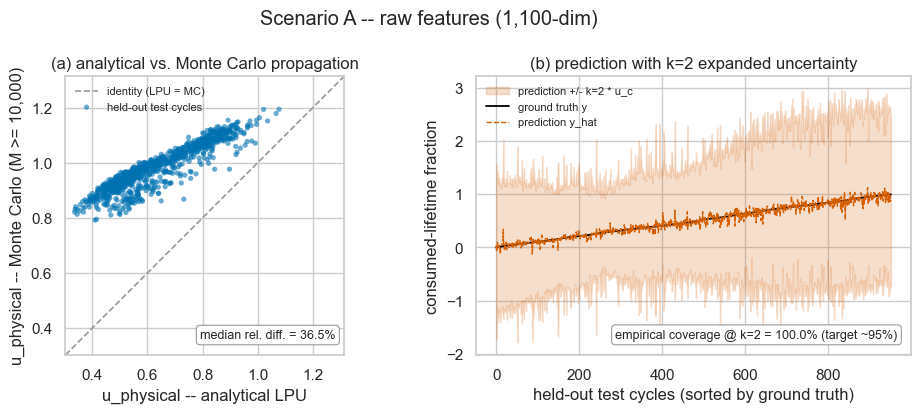

In [6]:
plot_validation(r_raw, "Scenario A -- raw features (1,100-dim)")


## Scenario B — trimmed features (`build_trimmed_dataset()`)

Same as `case_study_A_feature_trimming.ipynb`: recompute the settling length `K` per channel (the
leading within-cycle samples that are a measurement/DAQ acquisition transient, not a degradation
signal -- see `case_study_A_eda_outliers.ipynb`), then drop those `K` samples for Pneumatic
pressure, Velocity and Axial force before assembling the feature vector. Active current (`K=1`)
is left untouched, matching the original recommendation.


In [7]:
BASELINE_FROM = 20
SPIKE_RATIO = 5.0


def channel_block(arr, name):
    i = CHANNEL_NAMES.index(name)
    return arr[:, i * D:(i + 1) * D]


settle_K = {}
for name in CHANNEL_NAMES:
    block = channel_block(X, name)
    dev = np.abs(block - np.median(block, axis=1, keepdims=True))
    pos_mean_dev = dev.mean(axis=0)
    baseline = np.median(pos_mean_dev[BASELINE_FROM:])
    K = 0
    for p in range(len(pos_mean_dev)):
        if pos_mean_dev[p] > SPIKE_RATIO * baseline:
            K = p + 1
        else:
            break
    settle_K[name] = K

TRIM_CHANNELS = ["Pneumatic pressure", "Velocity", "Axial force"]


def build_trimmed_dataset(X, UX, channel_names, D, trim_channels, settle_K):
    x_parts, u_parts, spans = [], [], {}
    col = 0
    for name in channel_names:
        block_x = channel_block(X, name)
        block_u = channel_block(UX, name)
        if name in trim_channels:
            K = settle_K[name]
            block_x, block_u = block_x[:, K:], block_u[:, K:]
        x_parts.append(block_x)
        u_parts.append(block_u)
        spans[name] = (col, col + block_x.shape[1])
        col += block_x.shape[1]
    return np.concatenate(x_parts, axis=1), np.concatenate(u_parts, axis=1), spans


X_trim, UX_trim, trim_spans = build_trimmed_dataset(X, UX, CHANNEL_NAMES, D, TRIM_CHANNELS, settle_K)
print(f"raw features:     {X.shape[1]}")
print(f"trimmed features: {X_trim.shape[1]}  (dropped "
      f"{sum(settle_K[n] for n in TRIM_CHANNELS)} columns: "
      + ", ".join(f"{n}=-{settle_K[n]}" for n in TRIM_CHANNELS) + ")")


raw features:     1100
trimmed features: 1084  (dropped 16 columns: Pneumatic pressure=-7, Velocity=-6, Axial force=-3)


In [8]:
r_trim, models_trim, preds_te_trim = run_pipeline(X_trim, UX_trim, "trimmed")
summary_trim = summarize(r_trim, "Scenario B: trimmed features")
summary_trim["n_features"] = X_trim.shape[1]


  [trimmed] seed 0 trained


  [trimmed] seed 1 trained


  [trimmed] seed 2 trained


  [trimmed] seed 3 trained


  [trimmed] seed 4 trained


...

  [trimmed] propagated 200/953 test cycles


  [trimmed] propagated 400/953 test cycles


  [trimmed] propagated 600/953 test cycles


  [trimmed] propagated 800/953 test cycles


  [trimmed] propagated 953/953 test cycles
=== Scenario B: trimmed features ===
  rmse                        : 0.0661
  r2                          : 0.9484
  mean_u_physical_lpu         : 0.6547
  mean_u_physical_mc          : 0.9099
  lpu_vs_mc_median_rel_diff   : 28.33%
  mean_u_training             : 0.0504
  mean_u_c                    : 0.6572
  coverage_k2                 : 100.00%


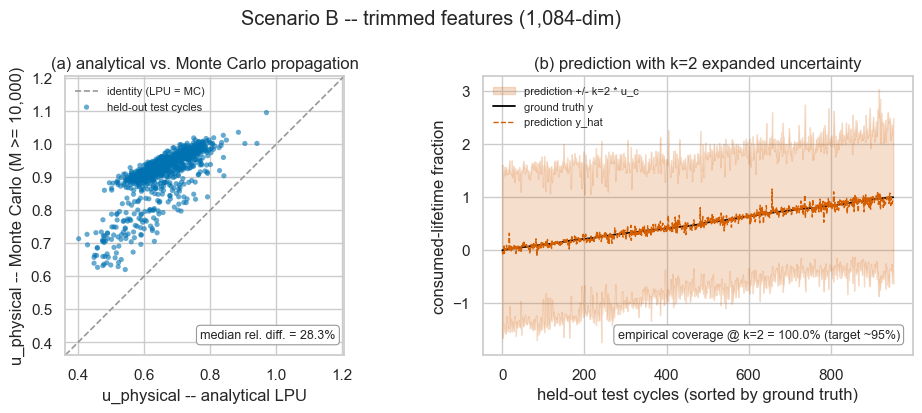

In [9]:
plot_validation(r_trim, "Scenario B -- trimmed features (1,084-dim)")


## Comparison — raw vs. trimmed, full uncertainty budget

`case_study_A_feature_trimming.ipynb` only compared point-prediction RMSE/R² between raw and
trimmed features. Here both scenarios went through the *entire* GUM pipeline, so the comparison
below also covers `u_physical` (LPU and MC), the LPU-vs-MC agreement check, `u_training`, the
combined `u_c`, and empirical coverage @ k=2 -- i.e. whether trimming the acquisition artifact
changes the uncertainty budget itself, not just the point prediction.


In [10]:
compare = pd.DataFrame([summary_raw, summary_trim]).set_index("scenario")
compare


,n_features,rmse,r2,mean_u_physical_lpu,mean_u_physical_mc,lpu_vs_mc_median_rel_diff,mean_u_training,mean_u_c,coverage_k2
scenario,,,,,,,,,
Scenario A: raw features,1100,0.0641,0.9514,0.6413,0.9841,0.3647,0.0493,0.6437,1.0
Scenario B: trimmed features,1084,0.0661,0.9484,0.6547,0.9099,0.2833,0.0504,0.6572,1.0


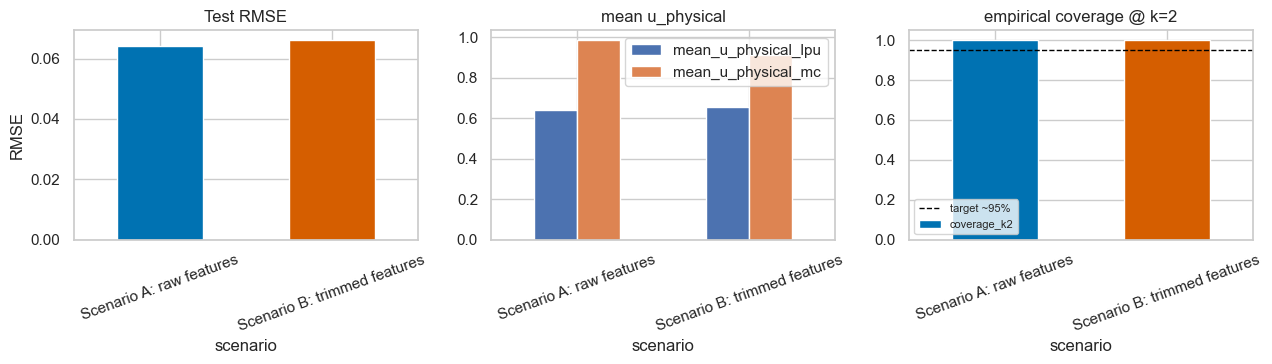

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

compare["rmse"].plot(kind="bar", ax=axes[0], color=["#0072B2", "#D55E00"])
axes[0].set_title("Test RMSE")
axes[0].set_ylabel("RMSE")
axes[0].tick_params(axis="x", rotation=20)

compare[["mean_u_physical_lpu", "mean_u_physical_mc"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("mean u_physical")
axes[1].tick_params(axis="x", rotation=20)

compare["coverage_k2"].plot(kind="bar", ax=axes[2], color=["#0072B2", "#D55E00"])
axes[2].axhline(0.95, color="black", ls="--", lw=1, label="target ~95%")
axes[2].set_title("empirical coverage @ k=2")
axes[2].legend(fontsize=8)
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()


In [12]:
delta_rmse = summary_trim["rmse"] - summary_raw["rmse"]
delta_cov = summary_trim["coverage_k2"] - summary_raw["coverage_k2"]
delta_uphys_mc = summary_trim["mean_u_physical_mc"] - summary_raw["mean_u_physical_mc"]
print(f"RMSE        : raw={summary_raw['rmse']:.4f}  trimmed={summary_trim['rmse']:.4f}  delta={delta_rmse:+.4f}")
print(f"u_physical(MC): raw={summary_raw['mean_u_physical_mc']:.4f}  trimmed={summary_trim['mean_u_physical_mc']:.4f}  delta={delta_uphys_mc:+.4f}")
print(f"coverage@k2 : raw={summary_raw['coverage_k2']:.1%}  trimmed={summary_trim['coverage_k2']:.1%}  delta={delta_cov:+.1%}")


RMSE        : raw=0.0641  trimmed=0.0661  delta=+0.0020
u_physical(MC): raw=0.9841  trimmed=0.9099  delta=-0.0742
coverage@k2 : raw=100.0%  trimmed=100.0%  delta=+0.0%


In [13]:
# Uncomment to persist either scenario's results under its own filename
# (left disabled so re-running this notebook never overwrites the official
# case_study_A_results.csv behind the committed report/figure).
# cols = ["y_true", "y_hat", "u_physical_lpu", "u_physical_mc", "u_training", "u_c", "covered_k2"]
# np.savetxt("case_study_A_results_notebook_raw.csv", r_raw, delimiter=",", header=",".join(cols))
# np.savetxt("case_study_A_results_notebook_trimmed.csv", r_trim, delimiter=",", header=",".join(cols))


## Summary

- Ran the full `case_study_A_analysis.py` pipeline (unmodified functions, same `cfg.seed=0`)
  twice under an identical train/test split: once on the raw 1,100-dim features (Scenario A) and
  once on the 1,084-dim trimmed features from `build_trimmed_dataset()` (Scenario B), each time
  recomputing the complete GUM budget -- `u_physical` (LPU + Monte Carlo), `u_training` (10-seed
  ensemble), combined `u_c`, and empirical coverage @ k=2 -- not just the point prediction.
- Scenario A's numbers are the reproduction check: compare the printed summary above against
  `README.md`'s headline results (RMSE 0.0641, R² 0.951, LPU-vs-MC median rel. diff. 36.5%,
  coverage 100.0%) -- with `cfg.seed=0` unchanged they should match closely.
- The Comparison section's table and bar charts are the evidence for whether trimming the
  start-of-cycle acquisition artifact changes more than just RMSE (as `case_study_A_feature_
  trimming.ipynb` already found to be a statistically marginal improvement): read the printed
  deltas above -- a materially smaller `u_physical` or a coverage closer to the ~95% target would
  support adopting the trim for the uncertainty budget specifically, not only for point accuracy.
- Neither scenario's results are written to disk by default -- re-running this notebook never
  overwrites `case_study_A_results.csv`, `case_study_A_report.md`'s numbers, or `zema_lpu_vs_mc.pdf`.
- For a closer look at the *inputs* behind this pipeline, see `case_study_A_eda.ipynb`,
  `case_study_A_eda_outliers.ipynb` and `case_study_A_feature_trimming.ipynb`.
